# Week 5b — Deep Dive on Keys (`K`), `k_norm`, Attention Sinks, and Full-Model `K+V` Compression

Week 5 revealed a dramatic finding: simply protecting **position 0** (`protect_pos0 = True`) dropped late-layer `K` compression error from **`+159–337%` PPL** down to **`+1.15–1.99%`** (`head`, `r = 0.25`) and from **`+57–120%`** to **`-0.15–0.25%`** (`head`, `r = 0.75`). It also dropped all-layer `V` (`joint`, `r = 0.25`) on Quechua from **`+350%`** to **`+7.86%`**.

This notebook investigates **why `K` reacts so strongly** and exploits `protect_pos0 = True` to unlock **full-model (`K`, `V`, and `K+V`)** analysis on **Qwen3-1.7B**:

1. **Part 1 — Mechanistic anatomy of `K` and the position-0 sink (~15 s):**
   - Per-position norm profile (`t = 0, 1, 2, 3, 4, 5, 10, 50`) pre- and post-`k_norm`.
   - Exact **cosine distortion after `k_norm`** of `K[0]` vs `K[pos >= 1]` under `head r=0.25`, `joint r=0.25`, and `head r=0.75` — tests whether Qwen3's `k_norm` RMSNorm amplifies direction rotation when the sink component is projected out.
   - Exact **per-head rank allocation** $\operatorname{tr}(P_{hh})$ inside `joint r = 0.25` (shows why `joint` beats `head` for both `K` and `V`).
2. **Part 2 — Four-way position-0 treatment on `K` (late layers):**
   - `skip1_proj_all`: Gram excludes pos 0, hook projects pos 0 (Weeks 3–4).
   - `gram_all_proj_all`: **Standard calibration (`SKIP_FIRST_TOKENS = 0`)** — Gram *includes* pos 0, hook projects pos 0. Tests whether naive full-sequence SVD *still* destroys the sink because pos 0 is only `1/512` of tokens with `0.33×` norm!
   - `protect_pos0`: leave token `0` untouched.
   - `protect_pos0_3`: leave tokens `0..3` untouched (StreamingLLM-style 4-sink check).
3. **Part 3 — Pre-`k_norm` (`k_proj`) vs Post-`k_norm` (`k_norm`) compression of `K`:**
   - Directly compares projecting `K` *before* vs *after* Qwen3's per-head RMSNorm (`k_norm`), both with and without `protect_pos0`.
4. **Part 4 — Depth-band sweep (`0–6`, `7–13`, `14–20`, `21–27`) and Full-Model `K+V` (`all 0–27` & `layers 3–27`) with `protect_pos0 = True`:**
   - Maps where cross-language bias lives across depth for `K` vs `V`.
   - Tests **true 4× full-model `K+V` KV-cache compression** (`all` layers and `layers 3–27`, skipping only the layers 0–2 sink spike) with `matched`, `en`, `multi_loo`, `multi`, and `mix_5k` (`w = 0.10`, ~5k tokens).

**Kaggle settings.** GPU T4 ×1, Internet On. Run once with `SMOKE_TEST = True` on CPU first.
Expected runtime on one T4: ~38–42 min full (`QUICK = True` ~15 min).

In [1]:
import os

SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"   # True for <30s CPU dry run
QUICK = False                                           # True: smaller grid (~15 min on T4)

MODEL_ID = "Qwen/Qwen3-1.7B"
LANGS = ["en", "es", "fi", "qu"]
WIKI_SNAPSHOT = "20231101"

SEQ_LEN = 512
CALIB_TOKENS = 150_000
EVAL_TOKENS = 60_000
LOW_BUDGET_WINDOWS = 10         # 10 * 512 = 5,120 tokens (~5k low-resource recipe)
MIX_WEIGHT = 0.10
MAX_TOKENS_PER_ARTICLE = 2048
MIN_CHARS_PER_ARTICLE = 500
MIN_FILL = 0.5

CALIB_BATCH = 8
EVAL_BATCH = 4
R_MAIN = 0.25
N_BOOT = 2000
SEED = 0

OUT_DIR = "/kaggle/working/kv_rank_week5b" if os.path.isdir("/kaggle/working") else "./kv_rank_week5b"
os.makedirs(OUT_DIR, exist_ok=True)

if SMOKE_TEST:
    LANGS = ["aa", "bb", "cc"]
    SEQ_LEN = 64
    CALIB_TOKENS = 64 * 24
    EVAL_TOKENS = 64 * 12
    LOW_BUDGET_WINDOWS = 4
    CALIB_BATCH, EVAL_BATCH, N_BOOT = 8, 4, 200

print(f"SMOKE_TEST={SMOKE_TEST} | QUICK={QUICK} | output -> {OUT_DIR}")

SMOKE_TEST=False | QUICK=False | output -> /kaggle/working/kv_rank_week5b


In [2]:
import itertools, json, math, time, zlib
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(SEED)
np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| torch:", torch.__version__)

device: cuda | torch: 2.11.0+cu130


## 1. Model & Hooks (`k_proj`, `v_proj`, and `k_norm`)

In [3]:
from transformers import AutoModelForCausalLM, AutoTokenizer

if SMOKE_TEST:
    from transformers import LlamaConfig, LlamaForCausalLM
    model = LlamaForCausalLM(LlamaConfig(
        vocab_size=1000, hidden_size=64, intermediate_size=128,
        num_hidden_layers=4, num_attention_heads=4,
        num_key_value_heads=2, max_position_embeddings=256,
    ))
    tokenizer = None
else:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
    half = torch.float16 if device == "cuda" else torch.float32
    try:
        model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=half)
    except TypeError:
        model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=half)

model.to(device).eval()

cfg = model.config
N_LAYERS = cfg.num_hidden_layers
N_KV = getattr(cfg, "num_key_value_heads", None) or cfg.num_attention_heads
HEAD_DIM = getattr(cfg, "head_dim", None) or cfg.hidden_size // cfg.num_attention_heads
D_KV = N_KV * HEAD_DIM

PROJ = {"K": [], "V": [], "K_post": []}
for name, mod in model.named_modules():
    if name.endswith("self_attn.k_proj"):
        PROJ["K"].append(mod)
    elif name.endswith("self_attn.v_proj"):
        PROJ["V"].append(mod)
    elif name.endswith("self_attn.k_norm"):
        PROJ["K_post"].append(mod)

assert len(PROJ["K"]) == len(PROJ["V"]) == N_LAYERS
HAS_KNORM = len(PROJ["K_post"]) == N_LAYERS

# Four equal depth quartiles + full-model sets
q = max(1, N_LAYERS // 4)
BANDS = {
    "early": list(range(0, q)),
    "mid1":  list(range(q, 2 * q)),
    "mid2":  list(range(2 * q, 3 * q)),
    "late":  list(range(3 * q, N_LAYERS)),
}
LATE = BANDS["late"]
ALL_LAYERS = list(range(N_LAYERS))
NO_SINK_LAYERS = list(range(min(3, N_LAYERS - 1), N_LAYERS))   # layers 3..27 (skips the 0-2 norm spike)

print(f"layers={N_LAYERS} kv_heads={N_KV} head_dim={HEAD_DIM} has_k_norm={HAS_KNORM}")
print("bands:", {k: f"{v[0]}–{v[-1]}" for k, v in BANDS.items()}, f"| no_sink: {NO_SINK_LAYERS[0]}–{NO_SINK_LAYERS[-1]}")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

layers=28 kv_heads=8 head_dim=128 has_k_norm=True
bands: {'early': '0–6', 'mid1': '7–13', 'mid2': '14–20', 'late': '21–27'} | no_sink: 3–27


## 2. Wikipedia splits & single-pass multi-Gram collection

In a **single forward pass** per language calibration split, we simultaneously collect:
- `gram_skip1`: `K`, `V`, and `K_post` (post-`k_norm`) excluding position 0 (`SKIP_FIRST_TOKENS = 1`), plus a `5k` snapshot (`10` windows).
- `gram_all`: `K` and `V` **including** position 0 (`SKIP_FIRST_TOKENS = 0`, standard full-sequence SVD).
- `gram_skip4`: `K` excluding positions `0..3` (for the 4-sink check).

In [4]:
def wiki_splits(lang):
    from datasets import load_dataset
    ds = load_dataset("wikimedia/wikipedia", f"{WIKI_SNAPSHOT}.{lang}", split="train", streaming=True)
    ds = ds.shuffle(seed=SEED, buffer_size=2000)
    need = {"calib": CALIB_TOKENS // SEQ_LEN, "eval": EVAL_TOKENS // SEQ_LEN}
    win = {"calib": [], "eval": []}
    for row in ds:
        if len(row["text"]) < MIN_CHARS_PER_ARTICLE:
            continue
        split = "calib" if zlib.crc32(str(row["id"]).encode()) % 2 == 0 else "eval"
        if len(win[split]) >= need[split]:
            if all(len(win[s]) >= need[s] for s in win):
                break
            continue
        ids = tokenizer(row["text"], add_special_tokens=False)["input_ids"][:MAX_TOKENS_PER_ARTICLE]
        for i in range(0, len(ids) - SEQ_LEN + 1, SEQ_LEN):
            if len(win[split]) < need[split]:
                win[split].append(ids[i:i + SEQ_LEN])
    for s in win:
        if len(win[s]) < MIN_FILL * need[s]:
            raise RuntimeError(f"{lang}/{s}: only {len(win[s])}/{need[s]} windows")
    return {s: torch.tensor(w, dtype=torch.long) for s, w in win.items()}


def smoke_splits(lang):
    lo = {"aa": 0, "bb": 300, "cc": 600}[lang]
    g = torch.Generator().manual_seed(SEED + lo)
    mk = lambda n: torch.randint(lo, lo + 300, (n // SEQ_LEN, SEQ_LEN), generator=g)
    return {"calib": mk(CALIB_TOKENS), "eval": mk(EVAL_TOKENS)}


data = {}
for lang in LANGS:
    t0 = time.time()
    data[lang] = (smoke_splits if SMOKE_TEST else wiki_splits)(lang)
    print(f"{lang}: calib {tuple(data[lang]['calib'].shape)}  eval {tuple(data[lang]['eval'].shape)}  ({time.time()-t0:.0f}s)")


def _to_btd(out):
    # Normalizes both (B, T, D_KV) from k_proj/v_proj and (B, T, N_KV, HEAD_DIM) from k_norm -> (B, T, D_KV)
    if out.ndim == 4:
        return out.reshape(out.shape[0], out.shape[1], D_KV)
    return out


class MultiGramCollector:
    """Collects skip=1 (K, V, K_post), skip=0 (K, V), and skip=4 (K) in one forward pass."""
    def __init__(self, collect_extra=True):
        self.collect_extra = collect_extra
        kinds = ["K", "V"] + (["K_post"] if HAS_KNORM else [])
        self.kinds = kinds
        self.g_skip1 = {k: torch.zeros(N_LAYERS, D_KV, D_KV, dtype=torch.float64, device=device) for k in kinds}
        self.n_skip1 = 0
        if collect_extra:
            self.g_all = {k: torch.zeros(N_LAYERS, D_KV, D_KV, dtype=torch.float64, device=device) for k in ("K", "V")}
            self.n_all = 0
            self.g_skip4 = {"K": torch.zeros(N_LAYERS, D_KV, D_KV, dtype=torch.float64, device=device)}
            self.n_skip4 = 0
        self.handles = []
        for k in kinds:
            for l, m in enumerate(PROJ[k]):
                self.handles.append(m.register_forward_hook(self._hook(k, l)))

    def _hook(self, kind, layer):
        def fn(mod, inp, out):
            x3 = _to_btd(out)
            x1 = x3[:, 1:, :].reshape(-1, D_KV).float()
            self.g_skip1[kind][layer] += (x1.T @ x1).double()
            if kind == "K" and layer == 0:
                self.n_skip1 += x1.shape[0]
            if self.collect_extra and kind in ("K", "V"):
                x0 = x3.reshape(-1, D_KV).float()
                self.g_all[kind][layer] += (x0.T @ x0).double()
                if kind == "K" and layer == 0:
                    self.n_all += x0.shape[0]
            if self.collect_extra and kind == "K":
                x4 = x3[:, 4:, :].reshape(-1, D_KV).float()
                self.g_skip4["K"][layer] += (x4.T @ x4).double()
                if layer == 0:
                    self.n_skip4 += x4.shape[0]
        return fn

    def snap_skip1(self):
        return {k: (g / self.n_skip1).cpu().numpy() for k, g in self.g_skip1.items()}

    def finish(self):
        for h in self.handles:
            h.remove()
        out = {"skip1": self.snap_skip1()}
        if self.collect_extra:
            out["all"] = {k: (g / self.n_all).cpu().numpy() for k, g in self.g_all.items()}
            out["skip4"] = {"K": (self.g_skip4["K"] / self.n_skip4).cpu().numpy()}
        return out


@torch.no_grad()
def window_nll(windows, batch):
    out = []
    for i in range(0, len(windows), batch):
        ids = windows[i:i + batch].to(device)
        logits = model(input_ids=ids, use_cache=False).logits[:, :-1].float()
        nll = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), ids[:, 1:].reshape(-1), reduction="none")
        out.append(nll.view(ids.shape[0], -1).mean(1).cpu())
        del logits, nll
    return torch.cat(out).numpy().astype(np.float64)


gram_calib, gram_calib_all, gram_calib_skip4, gram_5k = {}, {}, {}, {}
gram_eval, base_nll = {}, {}

for lang in LANGS:
    t0 = time.time()
    c = MultiGramCollector(collect_extra=True)
    w_cal = data[lang]["calib"]
    with torch.no_grad():
        for i in range(0, LOW_BUDGET_WINDOWS, CALIB_BATCH):
            model(input_ids=w_cal[i:min(i + CALIB_BATCH, LOW_BUDGET_WINDOWS)].to(device), use_cache=False)
        gram_5k[lang] = c.snap_skip1()
        for i in range(LOW_BUDGET_WINDOWS, len(w_cal), CALIB_BATCH):
            model(input_ids=w_cal[i:i + CALIB_BATCH].to(device), use_cache=False)
    res_cal = c.finish()
    gram_calib[lang] = res_cal["skip1"]
    gram_calib_all[lang] = res_cal["all"]
    gram_calib_skip4[lang] = res_cal["skip4"]

    ce = MultiGramCollector(collect_extra=False)
    base_nll[lang] = window_nll(data[lang]["eval"], EVAL_BATCH)
    gram_eval[lang] = ce.finish()["skip1"]
    if device == "cuda":
        torch.cuda.empty_cache()
    print(f"{lang}: baseline ppl={math.exp(base_nll[lang].mean()):.2f}  ({time.time()-t0:.0f}s)")

README.md:   0%|          | 0.00/131k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/41 [00:00<?, ?it/s]

en: calib (292, 512)  eval (117, 512)  (7s)
es: calib (292, 512)  eval (117, 512)  (5s)
fi: calib (292, 512)  eval (117, 512)  (4s)
qu: calib (292, 512)  eval (117, 512)  (7s)
en: baseline ppl=16.39  (82s)
es: baseline ppl=12.53  (91s)
fi: baseline ppl=15.89  (91s)
qu: baseline ppl=35.53  (90s)


In [5]:
def top_basis(G, r):
    lam, U = np.linalg.eigh(G)
    return U[:, ::-1][:, :r]


def blocks(G):
    return [G[h * HEAD_DIM:(h + 1) * HEAD_DIM, h * HEAD_DIM:(h + 1) * HEAD_DIM] for h in range(N_KV)]


def make_projector(G_layer, scope, f):
    if scope == "head":
        r = max(1, round(f * HEAD_DIM))
        P = np.stack([(lambda U: U @ U.T)(top_basis(B, r)) for B in blocks(G_layer)])
    else:
        r = max(1, round(f * D_KV))
        U = top_basis(G_layer, r)
        P = U @ U.T
    return torch.tensor(P, dtype=next(model.parameters()).dtype, device=device)


def project_hook(P, scope, protect_first=0):
    def fn(mod, inp, out):
        orig_shape = out.shape
        x3 = _to_btd(out)
        tail = x3[:, protect_first:, :] if protect_first > 0 else x3
        if scope == "head":
            B, T, _ = tail.shape
            proj = torch.einsum("btnd,nde->btne", tail.reshape(B, T, N_KV, HEAD_DIM), P).reshape(B, T, D_KV)
        else:
            proj = tail @ P
        if protect_first > 0:
            merged = torch.cat([x3[:, :protect_first, :], proj], dim=1)
        else:
            merged = proj
        return merged.reshape(orig_shape)
    return fn


def run_config(tgt, gram_src, kind, scope, f, layers, protect_first=1):
    # kind in {"K", "V", "K_post", "KV"}
    sub_kinds = ("K", "V") if kind == "KV" else (kind,)
    handles = []
    for sk in sub_kinds:
        for l in layers:
            P = make_projector(gram_src[sk][l], scope, f)
            handles.append(PROJ[sk][l].register_forward_hook(project_hook(P, scope, protect_first=protect_first)))
    try:
        return window_nll(data[tgt]["eval"], EVAL_BATCH)
    finally:
        for h in handles:
            h.remove()


rng = np.random.default_rng(SEED)


def paired(a, b):
    d = a - b
    boots = d[rng.integers(0, len(d), size=(N_BOOT, len(d)))].mean(1)
    return float(d.mean()), float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))


def avg_grams(glist, kinds=("K", "V")):
    return {k: sum(g[k] for g in glist) / len(glist) for k in kinds if k in glist[0]}


def mix_grams(g_other, g_tgt, w, kinds=("K", "V")):
    return {k: (1.0 - w) * g_other[k] + w * g_tgt[k] for k in kinds if k in g_other}


def source_gram(src, tgt, kinds=("K", "V")):
    if src == "oracle":    return gram_eval[tgt]
    if src == "matched":   return gram_calib[tgt]
    if src == "multi":     return avg_grams([gram_calib[l] for l in LANGS], kinds)
    if src == "multi_loo": return avg_grams([gram_calib[l] for l in LANGS if l != tgt], kinds)
    if src == "mix_5k":
        g_loo = avg_grams([gram_calib[l] for l in LANGS if l != tgt], kinds)
        return mix_grams(g_loo, gram_5k[tgt], MIX_WEIGHT, kinds)
    return gram_calib[src]

## 3. Part 1 — Mechanistic Anatomy of `K` (fast, ~15 s)

Three measurements that explain *mechanistically* why `K` behaved so dramatically:
1. **Per-position norm profile (`t = 0..15`):** is *only* `t = 0` an outlier/sink, or `t = 1..3` too?
2. **`k_norm` cosine-distortion test:** when we project `k_proj` output (before `k_norm`) onto the `pos >= 1` basis, how severely does `k_norm` rotate `K[0]` compared to `K[pos >= 1]` under `head r=0.25`, `joint r=0.25`, and `head r=0.75`?
3. **Head-wise rank allocation inside `joint r = 0.25`:** for $P = U U^\top$, $\operatorname{tr}(P_{hh}) \in [0, d]$ is the exact effective rank `joint` allocates to KV head $h$ (vs. uniform `32.0` in `head` scope).

In [6]:
en_code, qu_code = LANGS[0], LANGS[-1]
POS_CHECK = [0, 1, 2, 3, 4, 5, 10, 20, 50] if SEQ_LEN >= 64 else [0, 1, 2, 3]
POS_CHECK = [p for p in POS_CHECK if p < SEQ_LEN]

@torch.no_grad()
def anatomy_k(lang, n_win=12):
    sub = data[lang]["eval"][:min(n_win, len(data[lang]["eval"]))]
    # Precompute projectors for late layers
    projs = {}
    for l in LATE:
        G = gram_calib[lang]["K"][l]
        projs[l] = {
            "head_r25": make_projector(G, "head", 0.25),
            "joint_r25": make_projector(G, "joint", 0.25),
            "head_r75": make_projector(G, "head", 0.75),
        }

    pos_norms = {k: torch.zeros(N_LAYERS, len(POS_CHECK), dtype=torch.float64, device=device)
                 for k in (["K", "V"] + (["K_post"] if HAS_KNORM else []))}
    cos_acc = {(l, tag, part): [0.0, 0] for l in LATE for tag in ("head_r25", "joint_r25", "head_r75") for part in ("pos0", "rest")}
    n_seq = [0]

    def mk_norm_hook(kind, l):
        def fn(mod, inp, out):
            x3 = _to_btd(out).float()
            for pi, p in enumerate(POS_CHECK):
                pos_norms[kind][l, pi] += x3[:, p, :].norm(dim=-1).double().sum()
            if kind == "K" and l == 0:
                n_seq[0] += x3.shape[0]
            # Exact cosine distortion after k_norm (or raw if no k_norm) on late layers
            if kind == "K" and l in LATE:
                B, T, _ = x3.shape
                kn = PROJ["K_post"][l] if HAS_KNORM else None
                raw_4d = out.reshape(B, T, N_KV, HEAD_DIM)
                ref = (kn(raw_4d) if kn is not None else raw_4d).float()
                for tag, P in projs[l].items():
                    if tag.startswith("head"):
                        pr = torch.einsum("btnd,nde->btne", raw_4d, P)
                    else:
                        pr = (out @ P).reshape(B, T, N_KV, HEAD_DIM)
                    est = (kn(pr) if kn is not None else pr).float()
                    cs = F.cosine_similarity(ref, est, dim=-1)   # (B, T, N_KV)
                    cos_acc[(l, tag, "pos0")][0] += cs[:, 0, :].sum().item()
                    cos_acc[(l, tag, "pos0")][1] += cs[:, 0, :].numel()
                    cos_acc[(l, tag, "rest")][0] += cs[:, 1:, :].sum().item()
                    cos_acc[(l, tag, "rest")][1] += cs[:, 1:, :].numel()
        return fn

    hs = []
    for k in pos_norms:
        for l, m in enumerate(PROJ[k]):
            hs.append(m.register_forward_hook(mk_norm_hook(k, l)))
    try:
        for i in range(0, len(sub), EVAL_BATCH):
            model(input_ids=sub[i:i + EVAL_BATCH].to(device), use_cache=False)
    finally:
        for h in hs:
            h.remove()

    norm_rows = []
    for k, mat in pos_norms.items():
        arr = (mat / n_seq[0]).cpu().numpy()
        for l in range(N_LAYERS):
            for pi, p in enumerate(POS_CHECK):
                norm_rows.append(dict(lang=lang, kind=k, layer=l, band="late" if l in LATE else "other",
                                      pos=p, norm=float(arr[l, pi])))
    cos_rows = []
    for (l, tag, part), (s, cnt) in cos_acc.items():
        cos_rows.append(dict(lang=lang, layer=l, projector=tag, part=part, cos_sim=s / max(1, cnt)))
    return pd.DataFrame(norm_rows), pd.DataFrame(cos_rows)


norm_dfs, cos_dfs = [], []
for l in ([en_code, qu_code] if en_code != qu_code else [en_code]):
    nd, cd = anatomy_k(l)
    norm_dfs.append(nd); cos_dfs.append(cd)
pos_df = pd.concat(norm_dfs, ignore_index=True)
cos_df = pd.concat(cos_dfs, ignore_index=True)
pos_df.to_csv(os.path.join(OUT_DIR, "part1_pos_norms.csv"), index=False)
cos_df.to_csv(os.path.join(OUT_DIR, "part1_knorm_cosine.csv"), index=False)

print("=== Mean cosine similarity AFTER k_norm (late layers): pos 0 vs pos >= 1 ===")
display(cos_df.groupby(["lang", "projector", "part"]).cos_sim.mean().unstack().round(4))

# Per-head rank allocation inside joint r=0.25 projector (and head Frobenius energy share)
alloc_rows = []
for kind in ("K", "V"):
    for l in range(N_LAYERS):
        G = gram_calib[en_code][kind][l]
        r = max(1, round(R_MAIN * D_KV))
        U = top_basis(G, r)
        P = U @ U.T
        tot_tr = float(np.trace(G)) + 1e-12
        for h in range(N_KV):
            sl = slice(h * HEAD_DIM, (h + 1) * HEAD_DIM)
            alloc_rows.append(dict(
                kind=kind, layer=l, band="late" if l in LATE else "other", head=h,
                joint_eff_rank=float(np.trace(P[sl, sl])),
                head_energy_share=float(np.trace(G[sl, sl]) / tot_tr),
            ))
alloc_df = pd.DataFrame(alloc_rows)
alloc_df.to_csv(os.path.join(OUT_DIR, "part1_joint_rank_alloc.csv"), index=False)
print("\n=== Joint r=0.25 effective rank per KV head (late layers, uniform head baseline = "
      f"{R_MAIN * HEAD_DIM:.1f}) ===")
display(alloc_df[alloc_df.band == "late"].groupby(["kind", "head"])[["joint_eff_rank", "head_energy_share"]].mean().round(2))

=== Mean cosine similarity AFTER k_norm (late layers): pos 0 vs pos >= 1 ===


part              pos0    rest
lang projector                
en   head_r25   0.6890  0.9580
     head_r75   0.8048  0.9936
     joint_r25  0.8246  0.9841
qu   head_r25   0.7018  0.9598
     head_r75   0.8150  0.9944
     joint_r25  0.8292  0.9873


=== Joint r=0.25 effective rank per KV head (late layers, uniform head baseline = 32.0) ===


joint_eff_rank  head_energy_share
kind head                                   
K    0              32.56               0.14
     1              31.52               0.12
     2              31.21               0.13
     3              31.56               0.13
     4              36.24               0.13
     5              34.55               0.12
     6              29.74               0.12
     7              28.62               0.12
V    0              37.69               0.14
     1              26.74               0.10
     2              33.84               0.14
     3              31.93               0.13
     4              30.38               0.11
     5              35.16               0.14
     6              28.44               0.12
     7              31.82               0.12

## 4. Part 2 — Four-Way Position-0 Treatment on `K` (Late Layers)

Crucial test: does **standard full-sequence SVD (`SKIP_FIRST_TOKENS = 0`)** fix `K`, or does position 0 have too little weight in the Gram matrix (`1/512` of tokens × `0.33²` energy) so standard SVD *still* blows up unless position 0 is explicitly protected?

We compare four treatments on late-layer `K` (matched basis):
1. `skip1_proj_all` (Weeks 3–4): Gram excludes pos 0, hook projects pos 0.
2. `gram_all_proj_all` (**Standard SVD**): Gram *includes* pos 0, hook projects pos 0.
3. `protect_pos0`: Gram excludes pos 0, hook leaves pos 0 untouched.
4. `protect_pos0_3`: Gram excludes pos 0..3, hook leaves pos 0..3 untouched.

In [7]:
p2_targets = LANGS if SMOKE_TEST else ([en_code, qu_code] if QUICK else [en_code, "fi", qu_code])
p2_settings = [("head", 0.25), ("joint", 0.25), ("head", 0.75)] if not QUICK else [("head", 0.25), ("joint", 0.25)]
p2_treatments = [
    ("skip1_proj_all",   "skip1", 0),
    ("gram_all_proj_all","all",   0),
    ("protect_pos0",     "skip1", 1),
    ("protect_pos0_3",   "skip4", 4),
]

cfgs2 = []
for treat, gtype, pfirst in p2_treatments:
    for scope, rf in p2_settings:
        # Skip protect_pos0_3 at r=0.75 to save ~2 min (already near 0% at protect_pos0)
        if treat == "protect_pos0_3" and rf == 0.75:
            continue
        for tgt in p2_targets:
            cfgs2.append((treat, gtype, pfirst, scope, rf, tgt))

print(f"Part 2: {len(cfgs2)} configurations")
nll2, rows2 = {}, []
t0 = time.time()
for i, (treat, gtype, pfirst, scope, rf, tgt) in enumerate(cfgs2):
    gsrc = {"skip1": gram_calib[tgt], "all": gram_calib_all[tgt], "skip4": gram_calib_skip4[tgt]}[gtype]
    nll = run_config(tgt, gsrc, "K", scope, rf, LATE, protect_first=pfirst)
    nll2[(treat, scope, rf, tgt)] = nll
    rows2.append(dict(
        treatment=treat, scope=scope, rank_frac=rf, target=tgt,
        ppl=math.exp(nll.mean()),
        ppl_increase_pct=100.0 * (math.exp(nll.mean() - base_nll[tgt].mean()) - 1.0),
    ))
    if (i + 1) % 6 == 0 or i + 1 == len(cfgs2):
        el = time.time() - t0
        print(f"  {i+1}/{len(cfgs2)}  {el/60:.1f} min elapsed, ~{el/(i+1)*(len(cfgs2)-i-1)/60:.1f} min left")

res2 = pd.DataFrame(rows2)
res2.to_csv(os.path.join(OUT_DIR, "part2_k_pos0_treatments.csv"), index=False)
print("\n=== Part 2: K (late layers, matched) — PPL increase (%) by position-0 treatment ===")
display(res2.pivot_table(index=["scope", "rank_frac", "target"], columns="treatment", values="ppl_increase_pct")[
    [t[0] for t in p2_treatments]
].round(2))

Part 2: 33 configurations
  6/33  2.3 min elapsed, ~10.2 min left
  12/33  4.3 min elapsed, ~7.6 min left
  18/33  6.6 min elapsed, ~5.5 min left
  24/33  8.8 min elapsed, ~3.3 min left
  30/33  10.9 min elapsed, ~1.1 min left
  33/33  12.1 min elapsed, ~0.0 min left

=== Part 2: K (late layers, matched) — PPL increase (%) by position-0 treatment ===


treatment               skip1_proj_all  gram_all_proj_all  protect_pos0  \
scope rank_frac target                                                    
head  0.25      en              175.77             169.72          1.38   
                fi              337.13             327.62          1.15   
                qu              158.65             153.15          1.99   
      0.75      en               68.83              53.28         -0.15   
                fi              119.62              88.29          0.07   
                qu               57.28              41.63          0.25   
joint 0.25      en               47.73              19.06          0.18   
                fi               78.54              28.10          0.41   
                qu               37.37              12.14          0.69   

treatment               protect_pos0_3  
scope rank_frac target                  
head  0.25      en                1.32  
                fi                1.16  
                qu                1.97  
      0.75      en                 NaN  
                fi                 NaN  
                qu                 NaN  
joint 0.25      en                0.15  
                fi                0.38  
                qu                0.70

## 5. Part 3 — Pre-`k_norm` (`k_proj`) vs Post-`k_norm` (`k_norm`) Compression of `K`

Does compressing `K` **after** Qwen3's per-head RMSNorm (`k_norm`) behave differently from compressing **before** `k_norm` (`k_proj`), both with and without protecting position 0?
- If projecting *after* `k_norm` drastically reduces the `protect_pos0 = False` blow-up, then RMSNorm re-amplification of residual directions was a major contributor.
- Comparing `pre` vs `post` with `protect_pos0 = True` also shows where low-rank `K` compression is cleanest in QK-Norm architectures.

In [8]:
if not HAS_KNORM:
    print("Model has no self_attn.k_norm (e.g. Llama / smoke model) — skipping Part 3.")
    res3 = pd.DataFrame()
else:
    p3_targets = [en_code, qu_code] if QUICK else [en_code, "fi", qu_code]
    cfgs3 = []
    for kplace in ("K", "K_post"):
        for pfirst in (0, 1):
            for scope in ("head", "joint"):
                for tgt in p3_targets:
                    srcs = ["matched"] if tgt == en_code else ["matched", en_code]
                    for src in srcs:
                        # Reuse Part 2 matched pre-k_norm runs when already computed!
                        cfgs3.append((kplace, pfirst, scope, tgt, src))

    print(f"Part 3: {len(cfgs3)} total entries (reusing already-computed Part 2 runs where available)")
    nll3, rows3 = {}, []
    t0 = time.time()
    n_run = 0
    for kplace, pfirst, scope, tgt, src in cfgs3:
        reused = None
        if kplace == "K" and src == "matched":
            tkey = "skip1_proj_all" if pfirst == 0 else "protect_pos0"
            reused = nll2.get((tkey, scope, R_MAIN, tgt))
        if reused is not None:
            nll = reused
        else:
            nll = run_config(tgt, source_gram(src, tgt, kinds=(kplace,)), kplace, scope, R_MAIN, LATE, protect_first=pfirst)
            n_run += 1
        nll3[(kplace, pfirst, scope, tgt, src)] = nll
        rows3.append(dict(
            k_place="pre_knorm" if kplace == "K" else "post_knorm",
            protect_pos0=(pfirst > 0), scope=scope, target=tgt, source=src,
            ppl=math.exp(nll.mean()),
            ppl_increase_pct=100.0 * (math.exp(nll.mean() - base_nll[tgt].mean()) - 1.0),
        ))
    print(f"  Executed {n_run} new configs in {(time.time()-t0)/60:.1f} min")

    res3 = pd.DataFrame(rows3)
    d3 = []
    for r in res3.itertuples():
        kp = "K" if r.k_place == "pre_knorm" else "K_post"
        pf = 1 if r.protect_pos0 else 0
        if r.source == "matched":
            d3.append((np.nan, np.nan, np.nan))
        else:
            d3.append(paired(nll3[(kp, pf, r.scope, r.target, r.source)], nll3[(kp, pf, r.scope, r.target, "matched")]))
    res3[["delta_vs_matched", "ci_low", "ci_high"]] = np.array(d3)
    res3.to_csv(os.path.join(OUT_DIR, "part3_pre_vs_post_knorm.csv"), index=False)

    print("\n=== Part 3: K late (r=0.25) — pre_knorm vs post_knorm PPL increase (%) ===")
    display(res3.pivot_table(index=["protect_pos0", "scope", "target", "source"], columns="k_place", values="ppl_increase_pct").round(2))
    print("\n=== Part 3: Cross-language delta NLL (en vs matched) with protect_pos0=True ===")
    display(res3[(res3.protect_pos0) & (res3.source != "matched")][
        ["k_place", "scope", "target", "delta_vs_matched", "ci_low", "ci_high"]
    ].round(4))

Part 3: 40 total entries (reusing already-computed Part 2 runs where available)
  Executed 28 new configs in 10.5 min

=== Part 3: K late (r=0.25) — pre_knorm vs post_knorm PPL increase (%) ===


k_place                            post_knorm  pre_knorm
protect_pos0 scope target source                        
False        head  en     matched       72.17     175.77
                   fi     en           135.98     372.33
                          matched      153.30     337.13
                   qu     en            65.45     186.76
                          matched       65.98     158.65
             joint en     matched       36.05      47.73
                   fi     en            51.77      80.97
                          matched       63.08      78.54
                   qu     en            27.47      43.06
                          matched       26.35      37.37
True         head  en     matched       -0.37       1.38
                   fi     en             1.00       2.23
                          matched       -0.31       1.15
                   qu     en             2.44       4.98
                          matched        0.72       1.99
             joint en     matched       -0.33       0.18
                   fi     en            -0.26       0.44
                          matched       -0.04       0.41
                   qu     en             1.50       2.18
                          matched        0.28       0.69


=== Part 3: Cross-language delta NLL (en vs matched) with protect_pos0=True ===


,k_place,scope,target,delta_vs_matched,ci_low,ci_high
12,pre_knorm,head,fi,0.0106,0.0075,0.0140
14,pre_knorm,head,qu,0.0288,0.0260,0.0317
17,pre_knorm,joint,fi,0.0002,-0.0017,0.0023
19,pre_knorm,joint,qu,0.0147,0.0131,0.0165
32,post_knorm,head,fi,0.0131,0.0099,0.0163
34,post_knorm,head,qu,0.0170,0.0150,0.0190
37,post_knorm,joint,fi,-0.0022,-0.0044,0.0000
39,post_knorm,joint,qu,0.0120,0.0102,0.0140


## 6. Part 4 — Depth-Band Sweep (`K` vs `V`) and Full-Model `K+V` (`protect_pos0 = True`)

Now that `protect_pos0 = True` makes compression viable across the whole network, we run two key experiments at `r = 0.25` (4× KV-cache compression):

- **Part 4A (Depth bands: `early`, `mid1`, `mid2`, `late`, `joint` scope):** compresses `K` alone vs `V` alone in each quartile of the model (`en` vs `matched`) to map *where* in depth cross-language calibration bias occurs for `K` vs `V`.
- **Part 4B (Full-model `K+V` simultaneously: `all` layers `0–27` and `layers 3–27`, `joint` scope):** tests **true 4× KV-cache compression across the whole model** with `matched`, `en`, `multi_loo`, `multi`, and `mix_5k` (`w = 0.10`, ~5k tokens).

In [9]:
# --- Part 4A: Depth bands (K vs V, joint, r=0.25, protect_pos0=True) ---
p4a_targets = LANGS if SMOKE_TEST else ([en_code, qu_code] if QUICK else [en_code, "fi", qu_code])
cfgs4a = []
for band_name in ("early", "mid1", "mid2", "late"):
    for kind in ("K", "V"):
        for tgt in p4a_targets:
            srcs = ["matched"] if tgt == en_code else ["matched", en_code]
            for src in srcs:
                cfgs4a.append((band_name, kind, tgt, src))

print(f"Part 4A (depth bands): {len(cfgs4a)} configurations")
nll4a, rows4a = {}, []
t0 = time.time()
for i, (bname, kind, tgt, src) in enumerate(cfgs4a):
    # Reuse late K matched/en if already computed in Part 3
    reused = nll3.get(("K", 1, "joint", tgt, src)) if (HAS_KNORM and bname == "late" and kind == "K") else None
    nll = reused if reused is not None else run_config(tgt, source_gram(src, tgt), kind, "joint", R_MAIN, BANDS[bname], protect_first=1)
    nll4a[(bname, kind, tgt, src)] = nll
    rows4a.append(dict(
        band=bname, kind=kind, target=tgt, source=src,
        ppl=math.exp(nll.mean()),
        ppl_increase_pct=100.0 * (math.exp(nll.mean() - base_nll[tgt].mean()) - 1.0),
    ))
    if (i + 1) % 8 == 0 or i + 1 == len(cfgs4a):
        el = time.time() - t0
        print(f"  4A {i+1}/{len(cfgs4a)}  {el/60:.1f} min elapsed")

res4a = pd.DataFrame(rows4a)
d4a = []
for r in res4a.itertuples():
    if r.source == "matched":
        d4a.append((np.nan, np.nan, np.nan))
    else:
        d4a.append(paired(nll4a[(r.band, r.kind, r.target, r.source)], nll4a[(r.band, r.kind, r.target, "matched")]))
res4a[["delta_vs_matched", "ci_low", "ci_high"]] = np.array(d4a)
res4a["significant"] = (res4a.ci_low > 0) | (res4a.ci_high < 0)
res4a.to_csv(os.path.join(OUT_DIR, "part4a_depth_bands_kv.csv"), index=False)

print("\n=== Part 4A: Depth bands (joint, r=0.25, protect_pos0=True) — PPL increase (%) ===")
display(res4a.pivot_table(index=["kind", "target", "source"], columns="band", values="ppl_increase_pct")[
    ["early", "mid1", "mid2", "late"]
].round(2))
print("=== Part 4A: Foreign-basis delta NLL (en vs matched) across depth ===")
display(res4a[res4a.source != "matched"].pivot_table(index=["kind", "target"], columns="band", values="delta_vs_matched")[
    ["early", "mid1", "mid2", "late"]
].round(4))

# --- Part 4B: Full-model K+V simultaneously (all 0..27 & no_sink 3..27, joint, r=0.25, protect_pos0=True) ---
layer_sets_4b = {"all": ALL_LAYERS} if QUICK else {"all": ALL_LAYERS, "layers_3_27": NO_SINK_LAYERS}
p4b_targets = LANGS if not QUICK else [en_code, qu_code]
p4b_sources = ["matched", en_code, "multi_loo", "multi", "mix_5k"]

cfgs4b = []
for lset_name, layers in layer_sets_4b.items():
    for tgt in p4b_targets:
        for src in p4b_sources:
            if src == en_code and tgt == en_code:
                continue
            cfgs4b.append((lset_name, layers, tgt, src))

print(f"\nPart 4B (full-model K+V): {len(cfgs4b)} configurations")
nll4b, rows4b = {}, []
t0 = time.time()
for i, (lset_name, layers, tgt, src) in enumerate(cfgs4b):
    nll = run_config(tgt, source_gram(src, tgt), "KV", "joint", R_MAIN, layers, protect_first=1)
    nll4b[(lset_name, tgt, src)] = nll
    rows4b.append(dict(
        layers=lset_name, kind="KV", scope="joint", rank_frac=R_MAIN, target=tgt, source=src,
        ppl=math.exp(nll.mean()),
        ppl_increase_pct=100.0 * (math.exp(nll.mean() - base_nll[tgt].mean()) - 1.0),
    ))
    if (i + 1) % 6 == 0 or i + 1 == len(cfgs4b):
        el = time.time() - t0
        print(f"  4B {i+1}/{len(cfgs4b)}  {el/60:.1f} min elapsed, ~{el/(i+1)*(len(cfgs4b)-i-1)/60:.1f} min left")

res4b = pd.DataFrame(rows4b)
d4b = []
for r in res4b.itertuples():
    if r.source == "matched":
        d4b.append((np.nan, np.nan, np.nan))
    else:
        d4b.append(paired(nll4b[(r.layers, r.target, r.source)], nll4b[(r.layers, r.target, "matched")]))
res4b[["delta_vs_matched", "ci_low", "ci_high"]] = np.array(d4b)
res4b["significant"] = (res4b.ci_low > 0) | (res4b.ci_high < 0)
res4b.to_csv(os.path.join(OUT_DIR, "part4b_full_model_kv.csv"), index=False)

for lset_name in layer_sets_4b:
    print(f"\n=== Part 4B: Full-model K+V ({lset_name}, joint, r=0.25, protect_pos0=True) — PPL increase (%) ===")
    display(res4b[res4b.layers == lset_name].pivot_table(index="target", columns="source", values="ppl_increase_pct").round(2))
    print(f"=== Part 4B ({lset_name}): delta NLL vs matched ===")
    display(res4b[(res4b.layers == lset_name) & (res4b.source != "matched")].pivot_table(
        index="target", columns="source", values="delta_vs_matched"
    ).round(4))

Part 4A (depth bands): 40 configurations
  4A 8/40  3.2 min elapsed
  4A 16/40  6.5 min elapsed
  4A 24/40  9.7 min elapsed
  4A 32/40  12.1 min elapsed
  4A 40/40  14.2 min elapsed

=== Part 4A: Depth bands (joint, r=0.25, protect_pos0=True) — PPL increase (%) ===


band                 early  mid1   mid2  late
kind target source                           
K    en     matched   0.74  0.16  -0.21  0.18
     fi     en        5.44  0.29   0.67  0.44
            matched   2.13 -0.01   0.20  0.41
     qu     en        2.93  0.01  -0.64  2.18
            matched   1.25  0.49   0.37  0.69
V    en     matched  14.88 -0.05   0.45  3.14
     fi     en       85.55  6.08  45.45  8.06
            matched  18.84 -0.31  -2.19  0.49
     qu     en       34.89  2.21   3.63  8.00
            matched   7.77 -1.35  -2.65 -0.89

=== Part 4A: Foreign-basis delta NLL (en vs matched) across depth ===


band          early    mid1    mid2    late
kind target                                
K    fi      0.0319  0.0030  0.0047  0.0002
     qu      0.0165 -0.0048 -0.0101  0.0147
V    fi      0.4456  0.0622  0.3968  0.0726
     qu      0.2245  0.0355  0.0626  0.0859


Part 4B (full-model K+V): 38 configurations
  4B 6/38  5.4 min elapsed, ~28.9 min left
  4B 12/38  10.9 min elapsed, ~23.5 min left
  4B 18/38  16.3 min elapsed, ~18.1 min left
  4B 24/38  21.5 min elapsed, ~12.5 min left
  4B 30/38  26.6 min elapsed, ~7.1 min left
  4B 36/38  31.7 min elapsed, ~1.8 min left
  4B 38/38  33.4 min elapsed, ~0.0 min left

=== Part 4B: Full-model K+V (all, joint, r=0.25, protect_pos0=True) — PPL increase (%) ===


source,en,matched,mix_5k,multi,multi_loo
target,,,,,
en,NaN,35.38,86.41,59.04,189.62
es,174.45,26.07,44.92,34.83,59.24
fi,294.38,24.77,26.98,20.52,146.80
qu,77.76,9.86,15.23,10.95,48.28


... (2 outputs left out)


=== Part 4B: Full-model K+V (layers_3_27, joint, r=0.25, protect_pos0=True) — PPL increase (%) ===


source,en,matched,mix_5k,multi,multi_loo
target,,,,,
en,NaN,12.35,16.34,15.08,17.27
es,427.61,10.07,14.26,11.99,17.36
fi,260.38,3.11,7.27,4.79,84.69
qu,25.18,-1.32,0.51,-0.98,14.97


=== Part 4B (layers_3_27): delta NLL vs matched ===


source,en,mix_5k,multi,multi_loo
target,,,,
en,NaN,0.0349,0.0239,0.0428
es,1.5673,0.0374,0.0174,0.0642
fi,1.2514,0.0396,0.0163,0.5829
qu,0.2378,0.0183,0.0034,0.1527


## 7. Plots

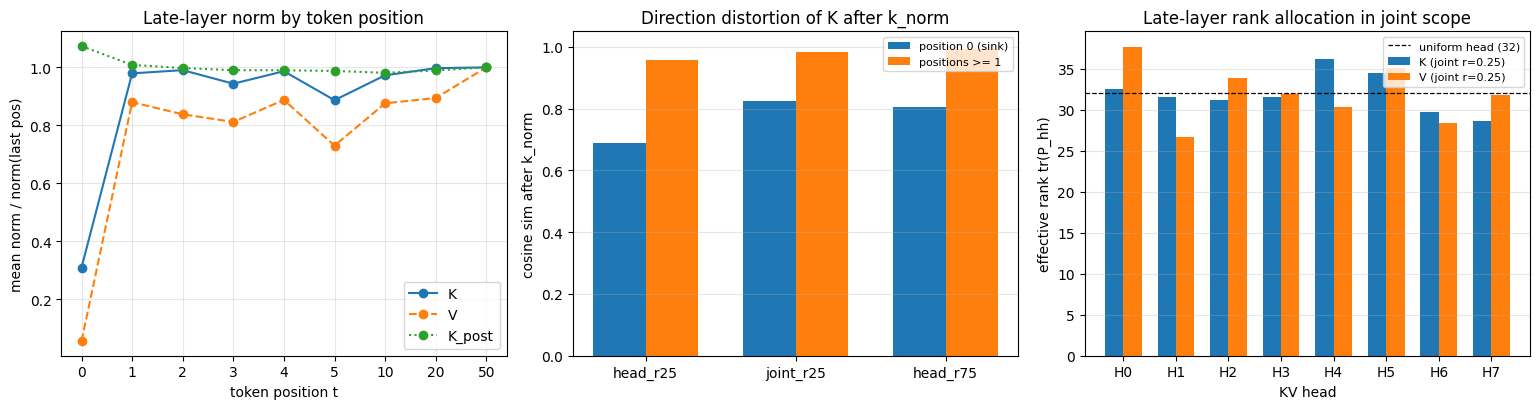

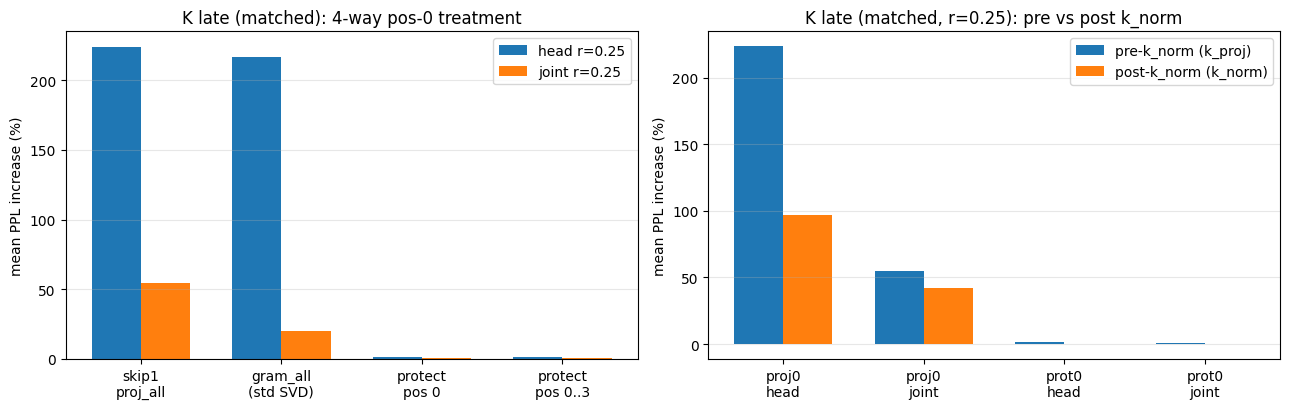

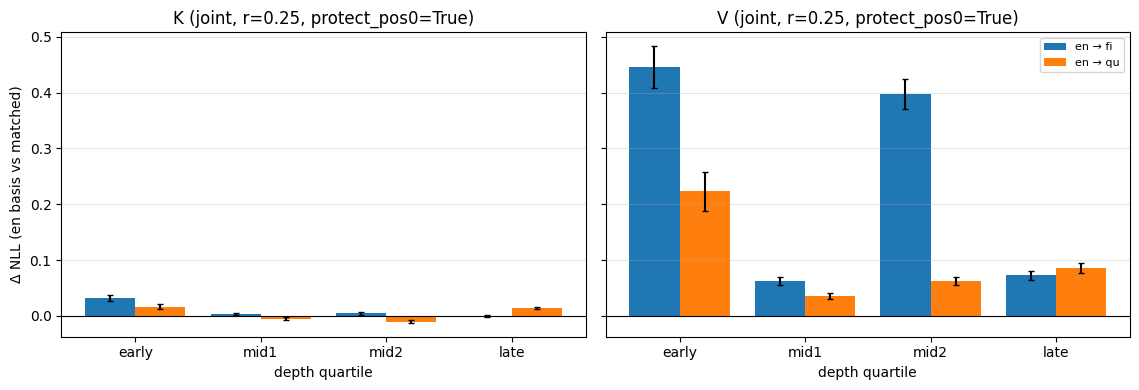

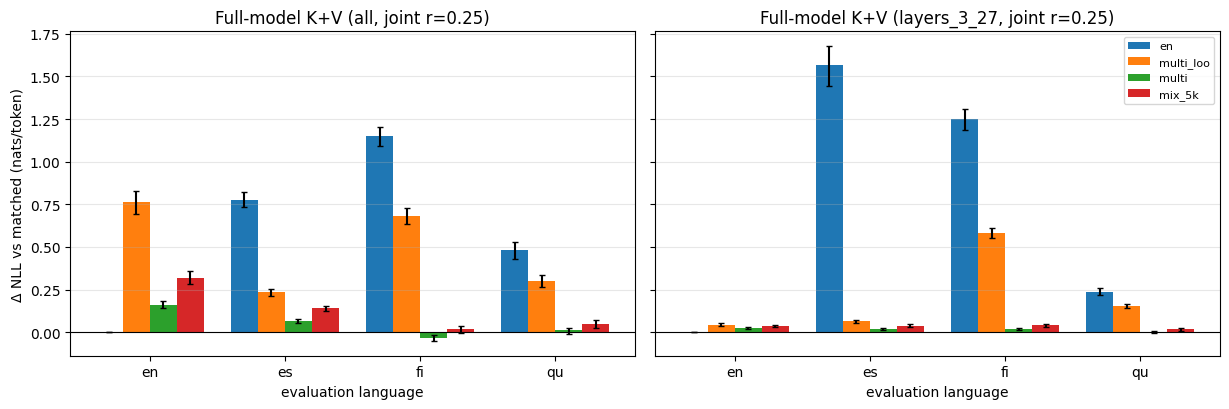

In [10]:
# Fig 1: Mechanistic anatomy of K (pos norms, k_norm cosine distortion, joint rank allocation)
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.2))

ax = axes[0]
for kind, ls in ([("K", "-"), ("V", "--")] + ([("K_post", ":")] if HAS_KNORM else [])):
    s = pos_df[(pos_df.lang == en_code) & (pos_df.kind == kind) & (pos_df.band == "late")].groupby("pos").norm.mean()
    s_norm = s / s.iloc[-1]
    ax.plot(range(len(s)), s_norm.values, "o" + ls, label=kind)
ax.set_xticks(range(len(POS_CHECK)), [str(p) for p in POS_CHECK])
ax.set_xlabel("token position t"); ax.set_ylabel("mean norm / norm(last pos)")
ax.set_title("Late-layer norm by token position"); ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
proj_order = ["head_r25", "joint_r25", "head_r75"]
x = np.arange(len(proj_order)); w = 0.35
sub_c = cos_df[cos_df.lang == en_code].groupby(["projector", "part"]).cos_sim.mean().unstack()
ax.bar(x - w/2, [sub_c.loc[p, "pos0"] for p in proj_order], w, label="position 0 (sink)")
ax.bar(x + w/2, [sub_c.loc[p, "rest"] for p in proj_order], w, label="positions >= 1")
ax.set_xticks(x, proj_order); ax.set_ylim(0, 1.05)
ax.set_ylabel("cosine sim after k_norm"); ax.set_title("Direction distortion of K after k_norm")
ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)

ax = axes[2]
al = alloc_df[alloc_df.band == "late"].groupby(["kind", "head"]).joint_eff_rank.mean().unstack(0)
x = np.arange(N_KV); w = 0.35
ax.bar(x - w/2, al["K"].values, w, label="K (joint r=0.25)")
ax.bar(x + w/2, al["V"].values, w, label="V (joint r=0.25)")
ax.axhline(R_MAIN * HEAD_DIM, color="k", ls="--", lw=0.9, label=f"uniform head ({R_MAIN*HEAD_DIM:g})")
ax.set_xticks(x, [f"H{h}" for h in range(N_KV)]); ax.set_xlabel("KV head")
ax.set_ylabel("effective rank tr(P_hh)"); ax.set_title("Late-layer rank allocation in joint scope")
ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fig1_k_pos0_anatomy.png"), dpi=150)
plt.show()

# Fig 2: 4-way pos-0 treatment + pre vs post k_norm
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

ax = axes[0]
treats = [t[0] for t in p2_treatments]
t_labels = ["skip1\nproj_all", "gram_all\n(std SVD)", "protect\npos 0", "protect\npos 0..3"]
x = np.arange(len(treats)); w = 0.35
for idx, (sc, rf) in enumerate([("head", 0.25), ("joint", 0.25)]):
    vals = [res2[(res2.treatment == t) & (res2.scope == sc) & (res2.rank_frac == rf)].ppl_increase_pct.mean() for t in treats]
    ax.bar(x + (idx - 0.5) * w, vals, w, label=f"{sc} r={rf:g}")
ax.set_xticks(x, t_labels); ax.set_ylabel("mean PPL increase (%)")
ax.set_title("K late (matched): 4-way pos-0 treatment"); ax.legend(); ax.grid(axis="y", alpha=0.3)

ax = axes[1]
if HAS_KNORM and len(res3):
    m3 = res3[res3.source == "matched"].groupby(["protect_pos0", "scope", "k_place"]).ppl_increase_pct.mean().unstack()
    labels3 = [f"{'prot0' if p else 'proj0'}\n{sc}" for p, sc in m3.index]
    x = np.arange(len(labels3)); w = 0.35
    ax.bar(x - w/2, m3["pre_knorm"].values, w, label="pre-k_norm (k_proj)")
    ax.bar(x + w/2, m3["post_knorm"].values, w, label="post-k_norm (k_norm)")
    ax.set_xticks(x, labels3); ax.set_ylabel("mean PPL increase (%)")
    ax.set_title("K late (matched, r=0.25): pre vs post k_norm"); ax.legend(); ax.grid(axis="y", alpha=0.3)
else:
    ax.text(0.5, 0.5, "No k_norm in model", ha="center", va="center")

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fig2_k_pos0_treatments_and_knorm.png"), dpi=150)
plt.show()

# Fig 3: Depth-band sweep (K vs V, en basis penalty vs matched, protect_pos0=True)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0), sharey=True)
band_order = ["early", "mid1", "mid2", "late"]
non_en = [l for l in p4a_targets if l != en_code]
x = np.arange(len(band_order)); w = 0.8 / max(1, len(non_en))
for ax, kind in zip(axes, ("K", "V")):
    for k, tgt in enumerate(non_en):
        sub = res4a[(res4a.kind == kind) & (res4a.target == tgt) & (res4a.source == en_code)].set_index("band").reindex(band_order)
        y = sub.delta_vs_matched.values
        err = np.vstack([y - sub.ci_low.values, sub.ci_high.values - y])
        ax.bar(x + (k - (len(non_en) - 1) / 2) * w, y, w, yerr=err, capsize=2, label=f"en → {tgt}")
    ax.axhline(0, color="k", lw=0.8); ax.set_xticks(x, band_order)
    ax.set_xlabel("depth quartile"); ax.set_title(f"{kind} (joint, r=0.25, protect_pos0=True)")
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Δ NLL (en basis vs matched)"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fig3_layer_bands_k_vs_v.png"), dpi=150)
plt.show()

# Fig 4: Full-model K+V compression (all 0..27 & layers 3..27)
show4b = [en_code, "multi_loo", "multi", "mix_5k"]
lsets4b = list(layer_sets_4b.keys())
fig, axes = plt.subplots(1, len(lsets4b), figsize=(6.2 * len(lsets4b), 4.2), sharey=True, squeeze=False)
w = 0.8 / len(show4b)
for ax, lset_name in zip(axes[0], lsets4b):
    x = np.arange(len(p4b_targets))
    for k, s in enumerate(show4b):
        sub = res4b[(res4b.layers == lset_name) & (res4b.source == s)].set_index("target").reindex(p4b_targets)
        y = np.nan_to_num(sub.delta_vs_matched.values)
        err = np.nan_to_num(np.vstack([sub.delta_vs_matched.values - sub.ci_low.values, sub.ci_high.values - sub.delta_vs_matched.values]))
        ax.bar(x + (k - (len(show4b) - 1) / 2) * w, y, w, yerr=err, capsize=2, label=s)
    ax.axhline(0, color="k", lw=0.8); ax.set_xticks(x, p4b_targets)
    ax.set_xlabel("evaluation language"); ax.set_title(f"Full-model K+V ({lset_name}, joint r=0.25)")
    ax.grid(axis="y", alpha=0.3)
axes[0][0].set_ylabel("Δ NLL vs matched (nats/token)"); axes[0][-1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fig4_full_model_kv_all_layers.png"), dpi=150)
plt.show()

## 8. Reading guide & transition to Llama-3.2

1. **Part 1 (`fig1_k_pos0_anatomy.png`):**
   - Look at panel 2 (`cosine sim after k_norm`): a large drop specifically for `position 0` compared to `positions >= 1` directly proves that `k_norm` amplifies angular distortion of the attention sink when `K[0]` is projected.
   - Look at panel 3 (`joint` rank allocation): heads with high $\operatorname{tr}(P_{hh})$ receive nearly full rank automatically, explaining why `joint` beats uniform `head` allocation.
2. **Part 2 (`part2_k_pos0_treatments.csv`):**
   - **Key check:** compare `gram_all_proj_all` (standard SVD including position 0) vs `protect_pos0`. If `gram_all_proj_all` *still* blows up `K`, that is a strong practical finding: **standard unweighted SVD calibration fails to preserve the position-0 sink even when position 0 is included in the calibration data**, so explicit sink protection is mandatory.
   - Compare `protect_pos0` vs `protect_pos0_3`: shows whether protecting token 0 alone is enough or if tokens 1–3 also act as sinks.
3. **Part 3 (`part3_pre_vs_post_knorm.csv`):**
   - Directly isolates Qwen3's `k_norm` role before comparing against **Llama-3.2** (which has no `k_norm`).
4. **Part 4 (`fig3_layer_bands_k_vs_v.png` & `fig4_full_model_kv_all_layers.png`):**
   - Shows whether `K` stays nearly language-agnostic across *all* depth bands while `V` carries the cross-language penalty — and whether **`joint` + `mix_5k` + `protect_pos0`** achieves viable **4× full-model `K+V` KV-cache compression** for Quechua and Finnish!